In [1]:
import sys
from pathlib import Path
_here = Path.cwd().resolve()
for _p in [_here, _here / "notebooks", _here.parent]:
    if (_p / "_nb_common.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
        break
import _nb_common as nb
nb.style()
rng = nb.set_seed()
nb.env_report()


NB_ENV_JSON:{"cryptography": "46.0.7", "cwd": "/Users/guykaptue/Downloads/insurance_federated_learning/notebooks", "dp_accounting": null, "executable": "/Users/guykaptue/Downloads/insurance_federated_learning/venv/bin/python", "flwr": "1.31.0", "matplotlib": "3.11.1", "mode": "light", "networkx": "3.6.1", "numpy": "1.26.4", "pandas": "2.2.3", "pgmpy": "0.1.26", "platform": "macOS-26.5.1-arm64-arm-64bit", "plotly": "5.24.1", "python": "3.11.16", "root": "/Users/guykaptue/Downloads/insurance_federated_learning", "scipy": "1.17.1", "seaborn": "0.13.2", "seed": 42, "sklearn": "1.5.2", "statsmodels": "0.14.6", "torch": "2.4.1"}


{'python': '3.11.16',
 'executable': '/Users/guykaptue/Downloads/insurance_federated_learning/venv/bin/python',
 'platform': 'macOS-26.5.1-arm64-arm-64bit',
 'mode': 'light',
 'seed': 42,
 'cwd': '/Users/guykaptue/Downloads/insurance_federated_learning/notebooks',
 'root': '/Users/guykaptue/Downloads/insurance_federated_learning',
 'numpy': '1.26.4',
 'pandas': '2.2.3',
 'scipy': '1.17.1',
 'sklearn': '1.5.2',
 'matplotlib': '3.11.1',
 'plotly': '5.24.1',
 'seaborn': '0.13.2',
 'torch': '2.4.1',
 'flwr': '1.31.0',
 'dp_accounting': None,
 'networkx': '3.6.1',
 'statsmodels': '0.14.6',
 'pgmpy': '0.1.26',
 'cryptography': '46.0.7'}

# Client identity and simulation isolation

**Purpose.** Inspect a recorded synthetic project artifact through the project APIs and show what it supports. Source: `docs/evidence/task7_flwr_rerun_2026-11-21/flwr-guard.log`. This notebook loads no external or real customer data.

**Interpretation limits.** Captured local synthetic Flower guard log. Unique node and partition mappings establish simulation mapping for this run only; a client_id is not authentication and this does not establish production isolation.


In [2]:
from dataclasses import dataclass
@dataclass(frozen=True)
class Cfg:
    seed: int = nb.SEED
    mode: str = nb.MODE
    n_max: int = 2000 if nb.MODE == "light" else 5000
cfg = Cfg()
cfg


Cfg(seed=42, mode='light', n_max=2000)

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
source_path = nb.ROOT / 'docs/evidence/task7_flwr_rerun_2026-11-21/flwr-guard.log'
source = None
if source_path.exists():
    try:
        if source_path.suffix == ".log":
            source = source_path.read_text(errors="replace")
            print(f"[evidence loaded] {source_path}")
        elif source_path.name == "privacy_state.json":
            source = json.loads(source_path.read_text())
            summary = json.loads((nb.ROOT/"docs/evidence/c6_run_2026-11-21/run_summary.json").read_text())
            print(f"[state loaded] {source_path}; run provenance:", {k:summary["run"].get(k) for k in ("git_sha","git_dirty","config_hash","dataset_version")})
        else:
            source = nb.load_artifact(source_path)
            print(f"[artifact loaded] {source_path}")
    except Exception as exc:
        print(f"[artifact skipped] {source_path}: {type(exc).__name__}: {exc}")
else:
    print(f"[artifact skipped] missing {source_path}")
records = []
import re
if source is not None:
    for line in source.splitlines():
        m=re.search(r"CLIENT_MAPPING node_id=(\d+) partition_id=(\d+) num_partitions=(\d+) client_id=([A-Za-z0-9_]+)",line)
        if m:
            node,part,total,cid=m.groups(); records.append((cid,int(part),int(node),np.nan,np.nan))
    print("captured mappings:",len(records),"distinct clients:",len({row[0] for row in records}))
    print("Guard checks passed: see end of source log for fit/evaluate identity counts.")

frame = pd.DataFrame(records, columns=["label", "x", "value", "lower", "upper"])
print("source rows:", len(frame))
frame.head()


[evidence loaded] /Users/guykaptue/Downloads/insurance_federated_learning/docs/evidence/task7_flwr_rerun_2026-11-21/flwr-guard.log
captured mappings: 12 distinct clients: 4
Guard checks passed: see end of source log for fit/evaluate identity counts.
source rows: 12


,label,x,value,lower,upper
0,switzerland_helvetia,3,665924036812971762,NaN,NaN
1,germany_allianz,0,2751235286524455779,NaN,NaN
2,belgium_ageas,2,7570777317964226237,NaN,NaN
3,france_axa,1,5440799484370231265,NaN,NaN
4,switzerland_helvetia,3,665924036812971762,NaN,NaN


[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/client_identity_and_isolation_bar.png


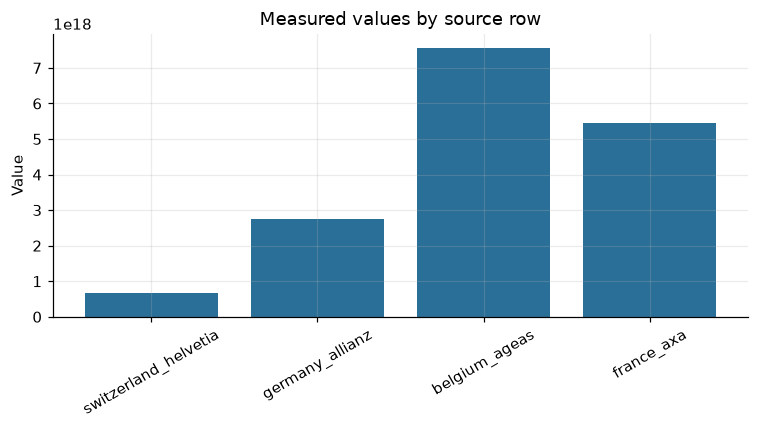

In [4]:
fig, ax = plt.subplots(figsize=(7,4))
if frame.empty: ax.text(.5,.5,"No measured artifact values available",ha="center",va="center",transform=ax.transAxes)
else: ax.bar(frame["label"].astype(str), frame["value"].astype(float), color="#2a6f97")
ax.set_title("Measured values by source row"); ax.set_ylabel("Value"); ax.tick_params(axis="x",rotation=30)
fig.tight_layout(); nb.save_fig(fig,"client_identity_and_isolation_bar"); plt.show()


[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/client_identity_and_isolation_scatter.png


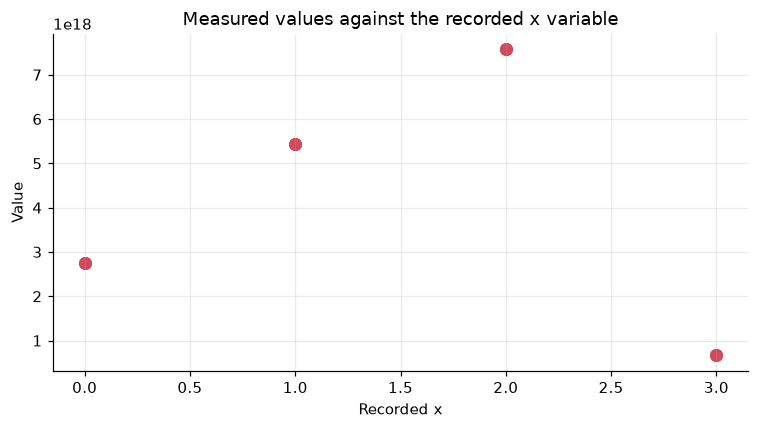

In [5]:
fig, ax = plt.subplots(figsize=(7,4))
if frame.empty: ax.text(.5,.5,"No measured artifact values available",ha="center",va="center",transform=ax.transAxes)
else: ax.scatter(frame["x"].astype(float), frame["value"].astype(float), s=55, color="#d1495b")
ax.set_title("Measured values against the recorded x variable"); ax.set_xlabel("Recorded x"); ax.set_ylabel("Value")
fig.tight_layout(); nb.save_fig(fig,"client_identity_and_isolation_scatter"); plt.show()


[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/client_identity_and_isolation_hist.png


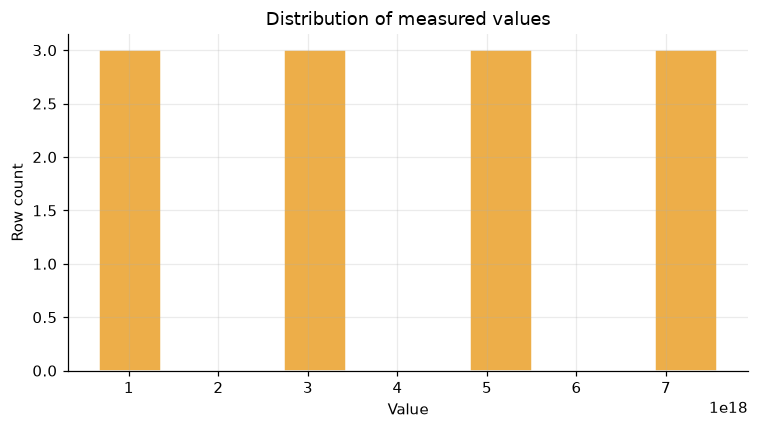

In [6]:
fig, ax = plt.subplots(figsize=(7,4))
values = pd.to_numeric(frame["value"], errors="coerce").dropna() if not frame.empty else pd.Series(dtype=float)
if values.empty: ax.text(.5,.5,"No measured artifact values available",ha="center",va="center",transform=ax.transAxes)
else: ax.hist(values, bins=min(10,max(1,len(values))), color="#edae49", edgecolor="white")
ax.set_title("Distribution of measured values"); ax.set_xlabel("Value"); ax.set_ylabel("Row count")
fig.tight_layout(); nb.save_fig(fig,"client_identity_and_isolation_hist"); plt.show()


**How to read this / what it shows.** This histogram summarizes only the available source rows. A missing-artifact message is shown instead of substituting sample values.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/client_identity_and_isolation_line.png


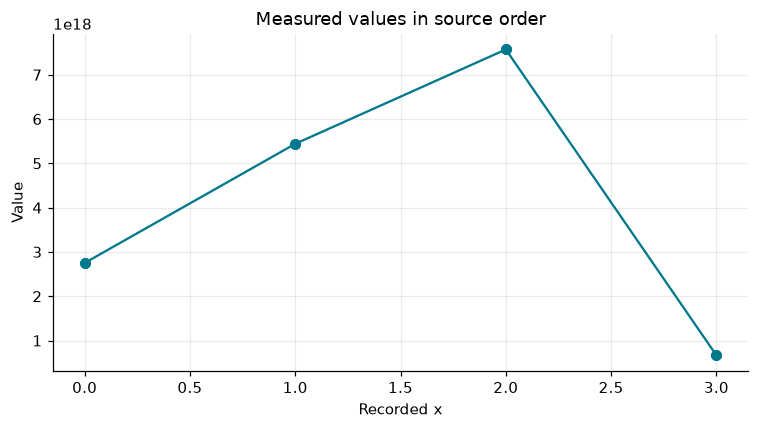

In [7]:
fig, ax = plt.subplots(figsize=(7,4))
if frame.empty: ax.text(.5,.5,"No measured artifact values available",ha="center",va="center",transform=ax.transAxes)
else:
    ordered = frame.sort_values("x")
    ax.plot(ordered["x"].astype(float), ordered["value"].astype(float), marker="o", color="#00798c")
ax.set_title("Measured values in source order"); ax.set_xlabel("Recorded x"); ax.set_ylabel("Value")
fig.tight_layout(); nb.save_fig(fig,"client_identity_and_isolation_line"); plt.show()


**How to read this / what it shows.** The line connects source rows sorted by their recorded x value to show ordering or trend within this artifact; it is not an extrapolation.

## Limitations and failure cases
- This is a synthetic, local evidence review; it is not production or multi-organization evidence.
- If the source artifact is missing or fails its provenance check, the notebook prints a skip message and its plots remain empty.
- The displayed summaries do not add privacy protection to their source records.

## References
- Project API and evidence source: `docs/evidence/task7_flwr_rerun_2026-11-21/flwr-guard.log`.
- Shared notebook helpers: `notebooks/_nb_common.py`.
